# Assignment 2: Detecting emotions with ML algorithms

## 1. FER2013 Baseline (20%)

### 1.1 Setup and experimental protocol
We adapt `z_load_split_fer2013.ipynb` for loading and
`baseline_fer2013_landmarks.ipynb` for the landmark + Random Forest baseline.

We compare all nine combinations of three feature types and three classifiers.
Training fits every learned transformation and classifier; PublicTest selects the
configuration by macro-F1 (balanced accuracy breaks ties). PrivateTest is used
only after the configurations are frozen. No augmentation, balancing, or extensive
tuning is applied here, leaving improvement experiments for Task 5.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import sys
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dlib
import joblib
from IPython.display import display
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
ROOT = Path.cwd()
assert (ROOT / 'emotion_detection_group11.ipynb').exists(), 'Run from the repository folder.'
DATA = ROOT / 'data'
CSV = next((p for p in [DATA / 'fer2013.csv', DATA / 'fer' / 'fer2013.csv'] if p.exists()), None)
if CSV is None:
    raise FileNotFoundError('Place fer2013.csv in data/ or data/fer/.')
PREDICTOR = ROOT / 'faceAndLandmarkModels' / 'shape_predictor_68_face_landmarks_GTX.dat'
assert PREDICTOR.exists(), f'Missing landmark predictor: {PREDICTOR}'
OUT = ROOT / 'results' / 'task1'
CACHE = DATA / 'feature_cache' / 'task1'
MODEL_DIR = ROOT / 'models' / 'task1'
for folder in [OUT, CACHE, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
EMOTIONS = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
LABELS = np.arange(7)
plt.rcParams.update({'figure.dpi': 110})
print('Python:', sys.executable)
print('Dataset:', CSV.relative_to(ROOT))

Python: c:\Users\alvar\anaconda3\envs\data_analysis\python.exe
Dataset: data\fer2013.csv


### 1.2 Load the official splits and inspect training data
Keep Training, PublicTest, and PrivateTest separate, exactly as in the supplied
loading notebook. Each image must contain 2,304 integer pixels between 0 and 255.
The test pixels remain unprocessed until final evaluation.

,split,images
0,train,28709
1,validation,3589
2,test,3589


,emotion,training_images
0,Angry,3995
1,Disgust,436
2,Fear,4097
3,Happy,7215
4,Sad,4830
5,Surprise,3171
6,Neutral,4965


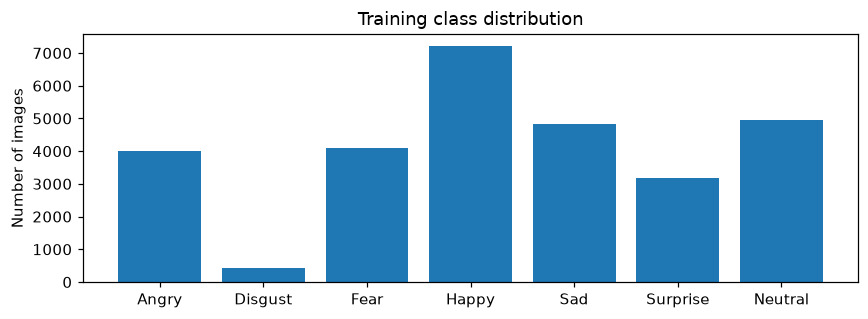

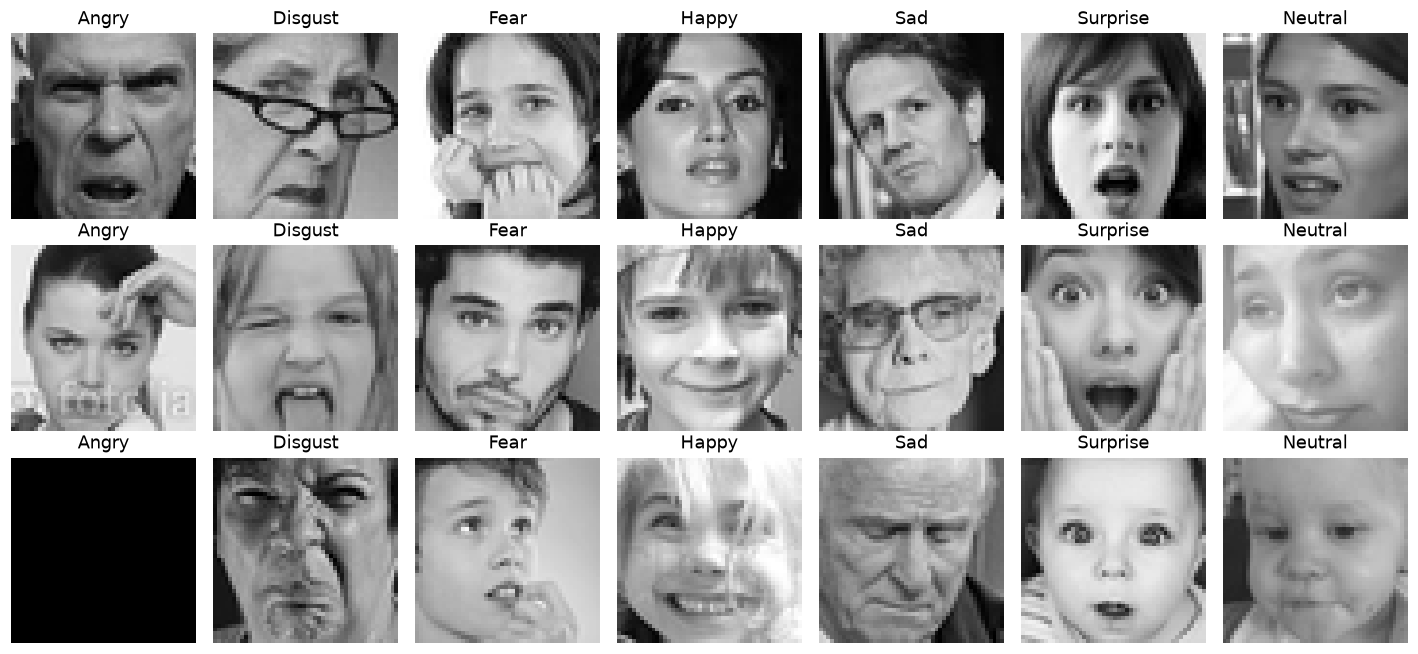

In [2]:
df = pd.read_csv(CSV)
assert {'emotion', 'pixels', 'Usage'}.issubset(df.columns)
assert not df[['emotion', 'pixels', 'Usage']].isna().any().any()
assert set(df['emotion'].unique()) == set(LABELS)
assert set(df['Usage'].unique()) == {'Training', 'PublicTest', 'PrivateTest'}
split_frames = {
    'train': df.loc[df.Usage == 'Training'].reset_index(drop=True),
    'validation': df.loc[df.Usage == 'PublicTest'].reset_index(drop=True),
    'test': df.loc[df.Usage == 'PrivateTest'].reset_index(drop=True),
}
display(pd.DataFrame({'split': split_frames.keys(),
                      'images': [len(frame) for frame in split_frames.values()]}))

def decode_images(frame):
    rows = [np.fromstring(s, sep=' ', dtype=np.int32) for s in frame['pixels']]
    if any(row.size != 48 * 48 for row in rows):
        raise ValueError('An image does not contain 2304 pixels.')
    pixels = np.stack(rows)
    assert pixels.min() >= 0 and pixels.max() <= 255
    return pixels.astype(np.uint8).reshape(-1, 48, 48)

images = {split: decode_images(split_frames[split]) for split in ['train', 'validation']}
y = {split: frame.emotion.to_numpy(dtype=int) for split, frame in split_frames.items()}
counts = pd.Series(y['train']).value_counts().reindex(LABELS)
display(pd.DataFrame({'emotion': EMOTIONS, 'training_images': counts.to_numpy()}))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(EMOTIONS, counts.to_numpy())
ax.set(title='Training class distribution', ylabel='Number of images')
plt.tight_layout()
plt.show()

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 7, figsize=(13, 6))
for label in LABELS:
    indices = rng.choice(np.flatnonzero(y['train'] == label), size=3, replace=False)
    for row, index in enumerate(indices):
        axes[row, label].imshow(images['train'][index], cmap='gray', vmin=0, vmax=255)
        axes[row, label].set_title(EMOTIONS[label])
        axes[row, label].axis('off')
plt.tight_layout()
plt.show()

### 1.3 Check and extract the supplied facial landmarks
FER images are already face crops, so the starter uses a fixed rectangle rather
than a face detector. We retain its rectangle and normalization: center the 68
points and scale each coordinate axis by its largest absolute value, yielding
136 features. A small denominator guard prevents division by zero.

Inspect the overlays: a predictor always returns points, but they may be inaccurate
on low-resolution, occluded, or rotated faces. Input to dlib stays uint8 in [0,255].

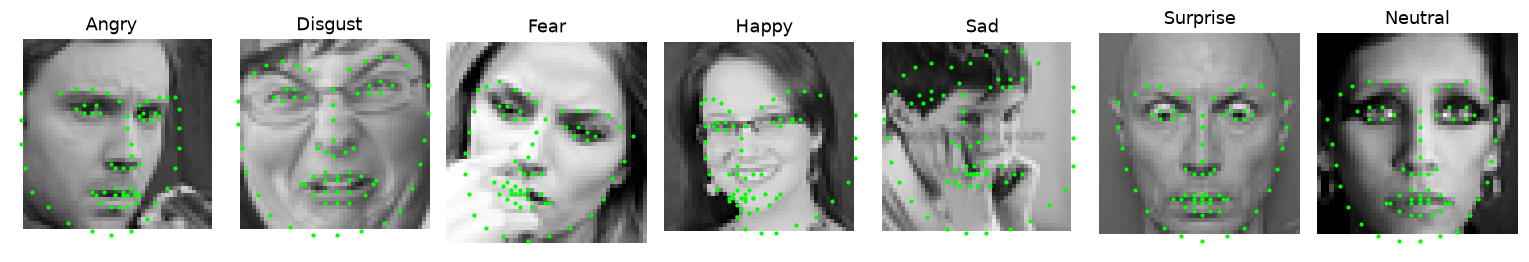

Loaded: landmarks_train_b21c23784e1fb3a7.npy
Loaded: landmarks_validation_78773a6e1ee1733c.npy


In [3]:
landmark_predictor = dlib.shape_predictor(str(PREDICTOR))
face_rect = dlib.rectangle(left=1, top=1, right=47, bottom=47)

def landmark_points(image):
    shape = landmark_predictor(np.ascontiguousarray(image, dtype=np.uint8), face_rect)
    return np.array([(p.x, p.y) for p in shape.parts()], dtype=np.float32)

def extract_landmarks(batch):
    features = []
    for image in batch:
        points = landmark_points(image)
        points -= points.mean(axis=0, keepdims=True)
        points /= np.maximum(np.abs(points).max(axis=0, keepdims=True), 1e-8)
        features.append(points.ravel())
    return np.stack(features)

fig, axes = plt.subplots(1, 7, figsize=(14, 3))
for label, ax in enumerate(axes):
    index = np.flatnonzero(y['train'] == label)[0]
    image = images['train'][index]
    points = landmark_points(image)
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.scatter(points[:, 0], points[:, 1], s=3, c='lime')
    ax.set_title(EMOTIONS[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

# Cache keys include the input rows, extraction settings, and predictor contents.
dataset_hash = hashlib.sha256(CSV.read_bytes()).hexdigest()
predictor_hash = hashlib.sha256(PREDICTOR.read_bytes()).hexdigest()
HOG_SETTINGS = dict(orientations=9, pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2), block_norm='L2-Hys', transform_sqrt=True)

def cached_features(kind, split, batch):
    settings = {'version': 1, 'dataset': dataset_hash, 'kind': kind, 'split': split,
                'predictor': predictor_hash if kind == 'landmarks' else None,
                'hog': HOG_SETTINGS if kind == 'hog' else None,
                'skimage': importlib.metadata.version('scikit-image'),
                'dlib': dlib.__version__}
    key = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:16]
    file = CACHE / f'{kind}_{split}_{key}.npy'
    if file.exists():
        result = np.load(file)
        print('Loaded:', file.name)
    else:
        start = perf_counter()
        if kind == 'landmarks':
            result = extract_landmarks(batch)
        elif kind == 'hog':
            result = np.stack([hog(image.astype(np.float32) / 255.0, **HOG_SETTINGS)
                               for image in batch]).astype(np.float32)
        else:
            raise ValueError(kind)
        np.save(file, result)
        print(f'Extracted {kind}/{split}: {result.shape}, {perf_counter()-start:.1f}s')
    assert result.shape[0] == len(batch) and np.isfinite(result).all()
    return result

features = {'landmarks': {
    split: cached_features('landmarks', split, images[split])
    for split in ['train', 'validation']
}}

### 1.4 Reproduce Random Forest + landmarks
These are the supplied settings: 300 trees, maximum depth 11, sqrt feature
sampling, entropy criterion, seed 42, and no class weighting. The starter computes
class weights but does not apply them. Its stored validation scores are approximately
0.44 accuracy, 0.37 balanced accuracy, and 0.38 macro-F1; our run is the evidence
used here. Small library-version differences can affect the scores.

,accuracy,balanced_accuracy,macro_f1
Provided RF + landmarks,0.446085,0.372204,0.374451


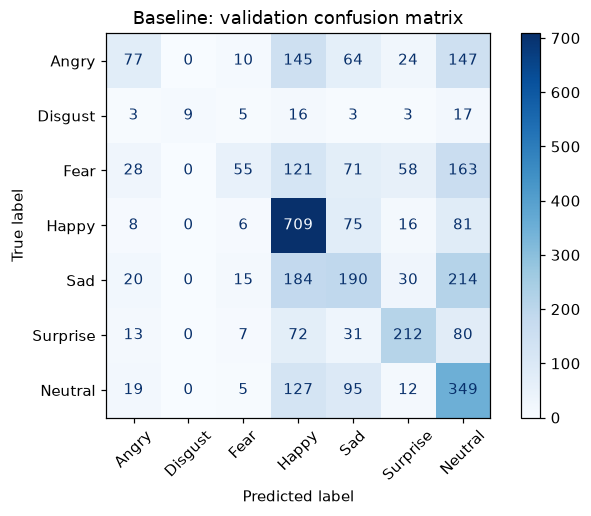

In [4]:
def new_random_forest():
    return RandomForestClassifier(n_estimators=300, max_depth=11,
                                  max_features='sqrt', criterion='entropy',
                                  random_state=SEED, n_jobs=-1)

def metric_scores(actual, predicted):
    return {'accuracy': accuracy_score(actual, predicted),
            'balanced_accuracy': balanced_accuracy_score(actual, predicted),
            'macro_f1': f1_score(actual, predicted, labels=LABELS,
                                 average='macro', zero_division=0)}

baseline_rf = new_random_forest()
start = perf_counter()
baseline_rf.fit(features['landmarks']['train'], y['train'])
baseline_fit_seconds = perf_counter() - start
baseline_predictions = baseline_rf.predict(features['landmarks']['validation'])
display(pd.DataFrame([metric_scores(y['validation'], baseline_predictions)],
                     index=['Provided RF + landmarks']))
ConfusionMatrixDisplay.from_predictions(y['validation'], baseline_predictions,
    labels=LABELS, display_labels=EMOTIONS, cmap='Blues', xticks_rotation=45)
plt.title('Baseline: validation confusion matrix')
plt.tight_layout()
plt.show()

### 1.5 HOG and PCA feature representations
HOG uses 9 orientations, 8×8 pixel cells, and 2×2 cell blocks: 900 features.
PCA uses 150 components of flattened pixels scaled to [0,1]. PCA centers the input
and is fitted on training images only; validation images only call `transform`.
These are fixed baseline choices, not test-selected parameters.

Loaded: hog_train_93ebf859c783514a.npy
Loaded: hog_validation_6fe681aa10f8c255.npy
PCA fit/transform: 1.5s
Variance retained: 92.3%


,feature,train_shape,validation_shape
0,landmarks,"(28709, 136)","(3589, 136)"
1,hog,"(28709, 900)","(3589, 900)"
2,pca,"(28709, 150)","(3589, 150)"


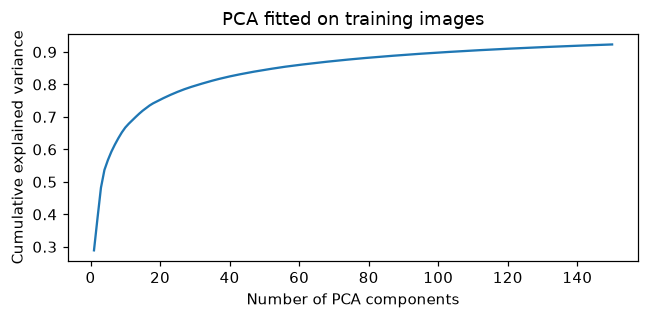

In [5]:
features['hog'] = {split: cached_features('hog', split, images[split])
                   for split in ['train', 'validation']}

def pixel_vectors(batch):
    return batch.reshape(len(batch), -1).astype(np.float32) / 255.0

pca = PCA(n_components=150, svd_solver='randomized', random_state=SEED)
start = perf_counter()
features['pca'] = {'train': pca.fit_transform(pixel_vectors(images['train']))}
features['pca']['validation'] = pca.transform(pixel_vectors(images['validation']))
print(f'PCA fit/transform: {perf_counter()-start:.1f}s')
print(f'Variance retained: {pca.explained_variance_ratio_.sum():.1%}')
display(pd.DataFrame([
    {'feature': name, 'train_shape': arrays['train'].shape,
     'validation_shape': arrays['validation'].shape}
    for name, arrays in features.items()]))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, 151), np.cumsum(pca.explained_variance_ratio_))
ax.set(xlabel='Number of PCA components', ylabel='Cumulative explained variance',
       title='PCA fitted on training images')
plt.tight_layout()
plt.show()

### 1.6 Train the nine configurations and compare validation scores
Logistic Regression and linear SVM use StandardScaler fitted inside their training
pipelines. Random Forest uses the feature vectors directly. LinearSVC is a linear
support vector machine; this experiment does not evaluate an RBF kernel.
We reuse the baseline forest rather than fitting the identical configuration twice.
The table records classifier fit time; shared feature extraction/PCA time is printed
above and is not included in that column. Convergence warnings should be resolved
before interpreting a run.

landmarks + Logistic Regression: macro-F1=0.3507
landmarks + Linear SVM: macro-F1=0.3045
landmarks + Random Forest: macro-F1=0.3745
hog + Logistic Regression: macro-F1=0.3991
hog + Linear SVM: macro-F1=0.3880
hog + Random Forest: macro-F1=0.3857
pca + Logistic Regression: macro-F1=0.2919
pca + Linear SVM: macro-F1=0.2712
pca + Random Forest: macro-F1=0.2911


,feature,classifier,accuracy,balanced_accuracy,macro_f1,fit_seconds
0,hog,Logistic Regression,0.4361,0.4017,0.3991,3.8297
1,hog,Linear SVM,0.4478,0.3836,0.3880,84.0667
2,hog,Random Forest,0.4464,0.3720,0.3857,71.8708
3,landmarks,Random Forest,0.4461,0.3722,0.3745,13.9126
4,landmarks,Logistic Regression,0.4316,0.3568,0.3507,2.1482
5,landmarks,Linear SVM,0.4244,0.3350,0.3045,8.0601
6,pca,Logistic Regression,0.3870,0.3040,0.2919,0.1254
7,pca,Random Forest,0.3745,0.2919,0.2911,33.3437
8,pca,Linear SVM,0.3831,0.2955,0.2712,1.0971


Selected using validation macro-F1: ('hog', 'Logistic Regression')


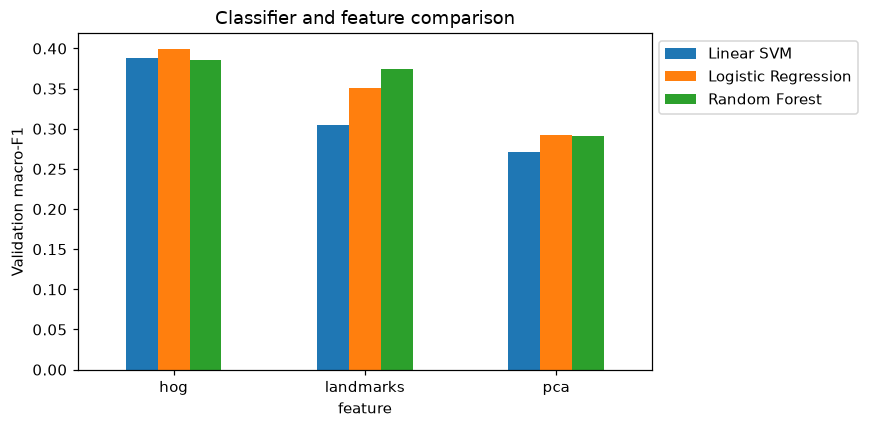

In [6]:
def new_classifier(name):
    if name == 'Logistic Regression':
        return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000,
                                                                  random_state=SEED))
    if name == 'Linear SVM':
        return make_pipeline(StandardScaler(), LinearSVC(C=0.01, dual=False,
                                                         max_iter=10000, random_state=SEED))
    if name == 'Random Forest':
        return new_random_forest()
    raise ValueError(name)

models, validation_predictions, rows = {}, {}, []
for feature_name, arrays in features.items():
    for classifier_name in ['Logistic Regression', 'Linear SVM', 'Random Forest']:
        key = (feature_name, classifier_name)
        if key == ('landmarks', 'Random Forest'):
            model, fit_seconds = baseline_rf, baseline_fit_seconds
        else:
            model = new_classifier(classifier_name)
            start = perf_counter()
            model.fit(arrays['train'], y['train'])
            fit_seconds = perf_counter() - start
        predictions = model.predict(arrays['validation'])
        models[key] = model
        validation_predictions[key] = predictions
        rows.append({'feature': feature_name, 'classifier': classifier_name,
                     **metric_scores(y['validation'], predictions),
                     'fit_seconds': fit_seconds})
        print(f'{feature_name} + {classifier_name}: macro-F1={rows[-1]["macro_f1"]:.4f}', flush=True)

validation_results = pd.DataFrame(rows).sort_values(
    ['macro_f1', 'balanced_accuracy'], ascending=False).reset_index(drop=True)
validation_results.to_csv(OUT / 'validation_results.csv', index=False)
display(validation_results.round(4))
best_key = tuple(validation_results.loc[0, ['feature', 'classifier']])
best_feature, best_classifier = best_key
print('Selected using validation macro-F1:', best_key)

fig, ax = plt.subplots(figsize=(8, 4))
validation_results.pivot(index='feature', columns='classifier', values='macro_f1').plot.bar(ax=ax)
ax.set(ylabel='Validation macro-F1', title='Classifier and feature comparison')
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(OUT / 'validation_comparison.png', bbox_inches='tight')
plt.show()

### 1.7 Validation error analysis for the selected configuration
Rows are actual emotions and columns predicted emotions. Row-normalized matrices
show class recall and make minority-class failures easier to see. The example
gallery is validation-only: inspect lighting, pose, occlusion, and ambiguous labels
without assuming that a wrong prediction proves a mislabeled image.

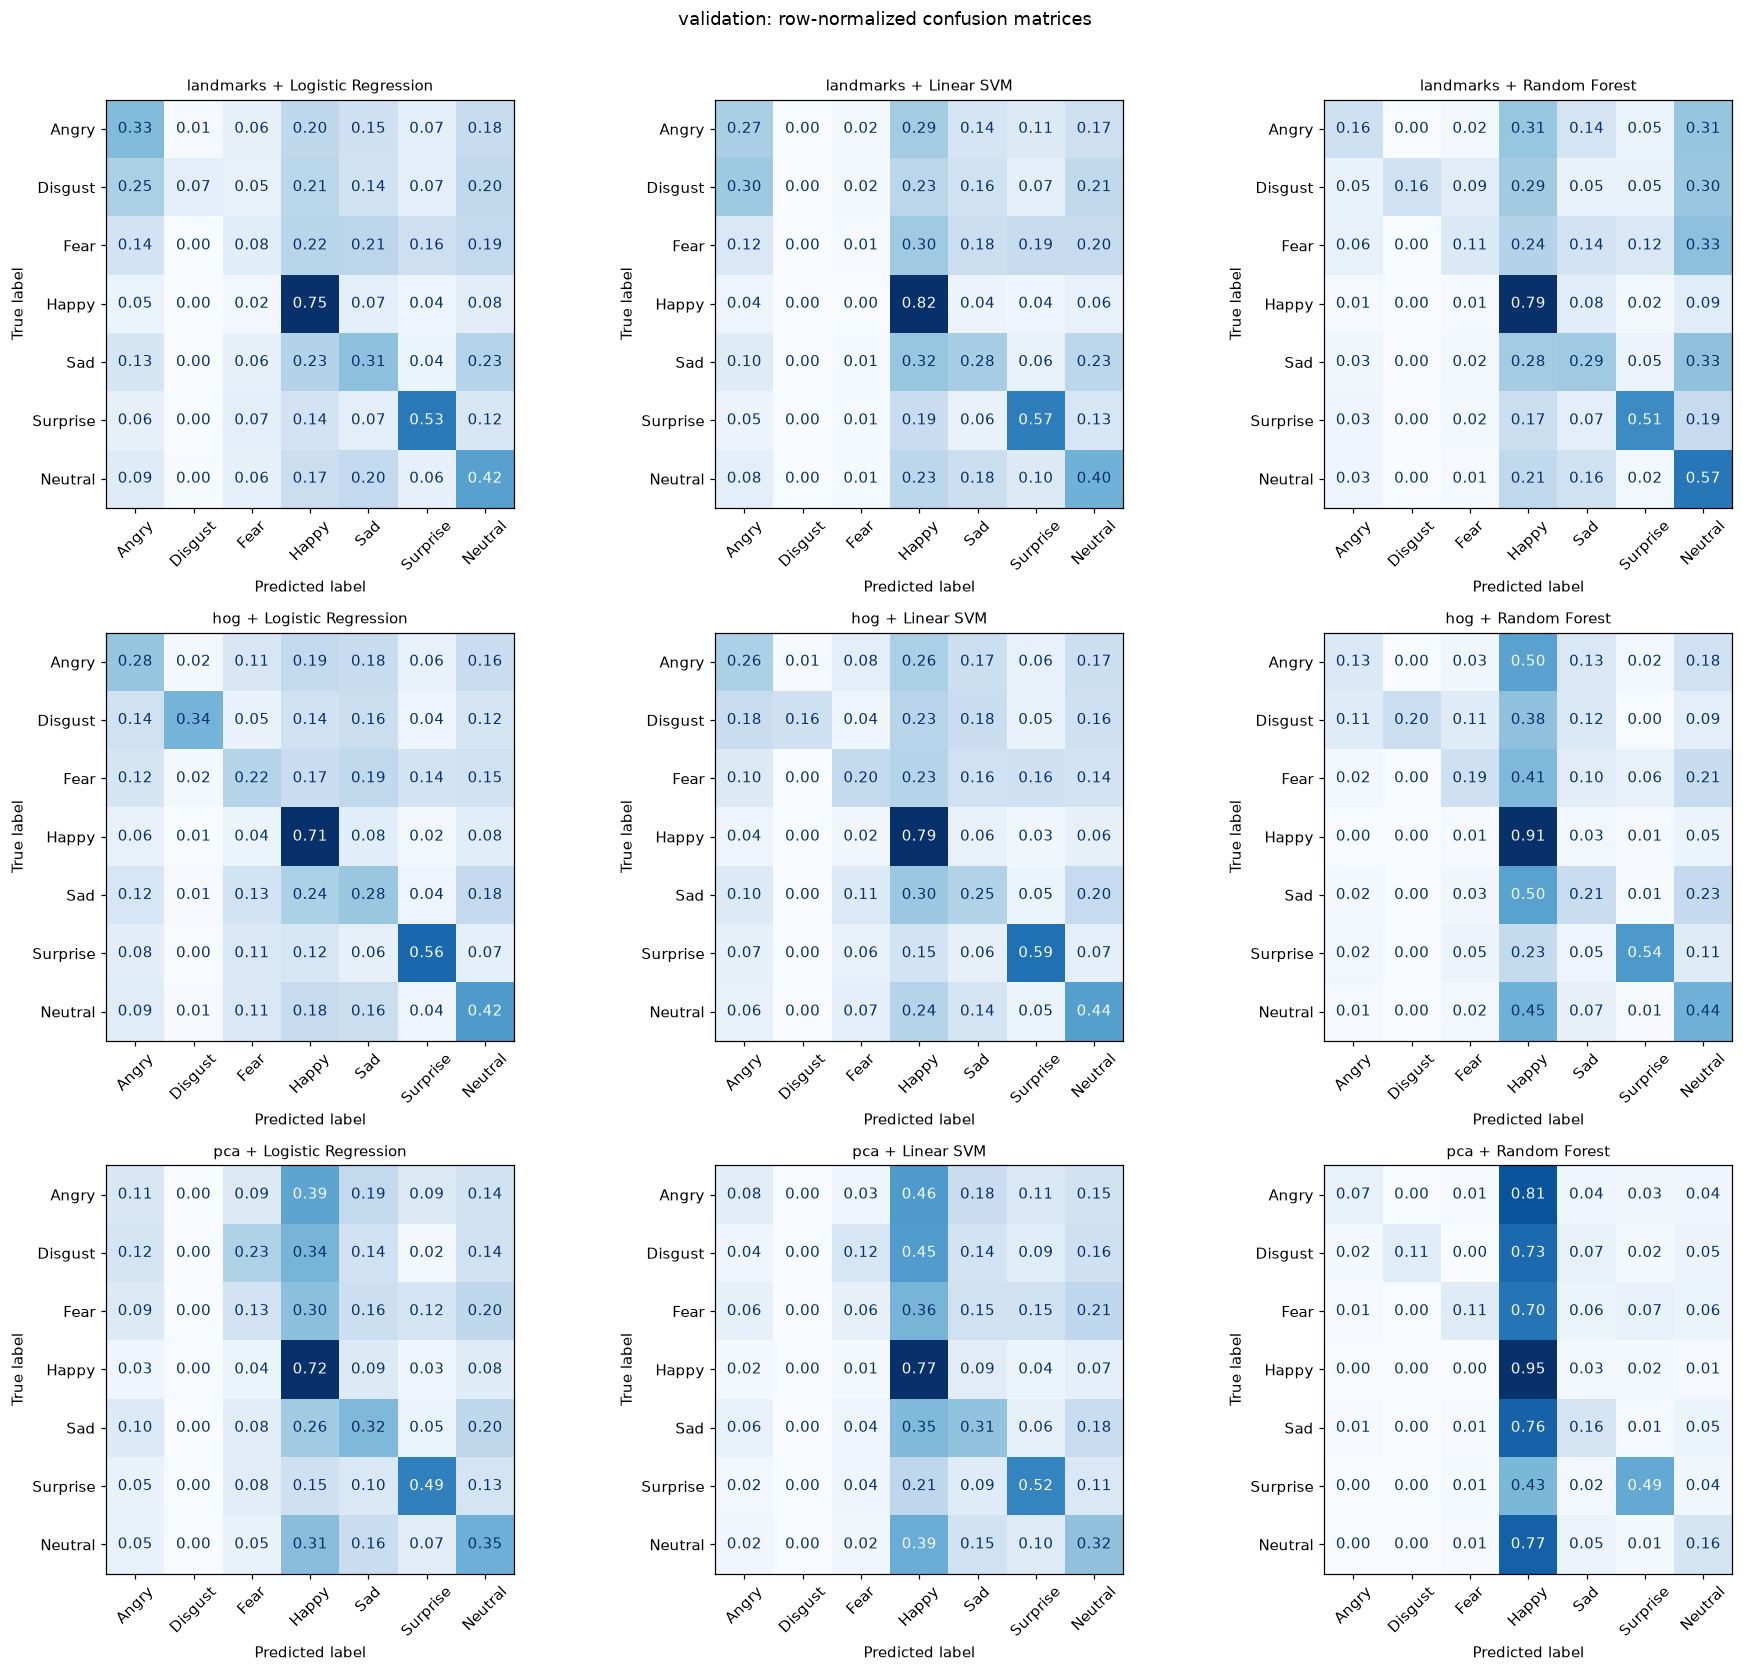

,precision,recall,f1-score,support
Angry,0.3220,0.2848,0.3023,467.0000
Disgust,0.3393,0.3393,0.3393,56.0000
Fear,0.2732,0.2198,0.2436,496.0000
Happy,0.5648,0.7106,0.6294,895.0000
Sad,0.3197,0.2757,0.2961,653.0000
Surprise,0.5825,0.5614,0.5718,415.0000
Neutral,0.4035,0.4201,0.4116,607.0000
accuracy,0.4361,0.4361,0.4361,0.4361
macro avg,0.4007,0.4017,0.3991,3589.0000
weighted avg,0.4196,0.4361,0.4248,3589.0000


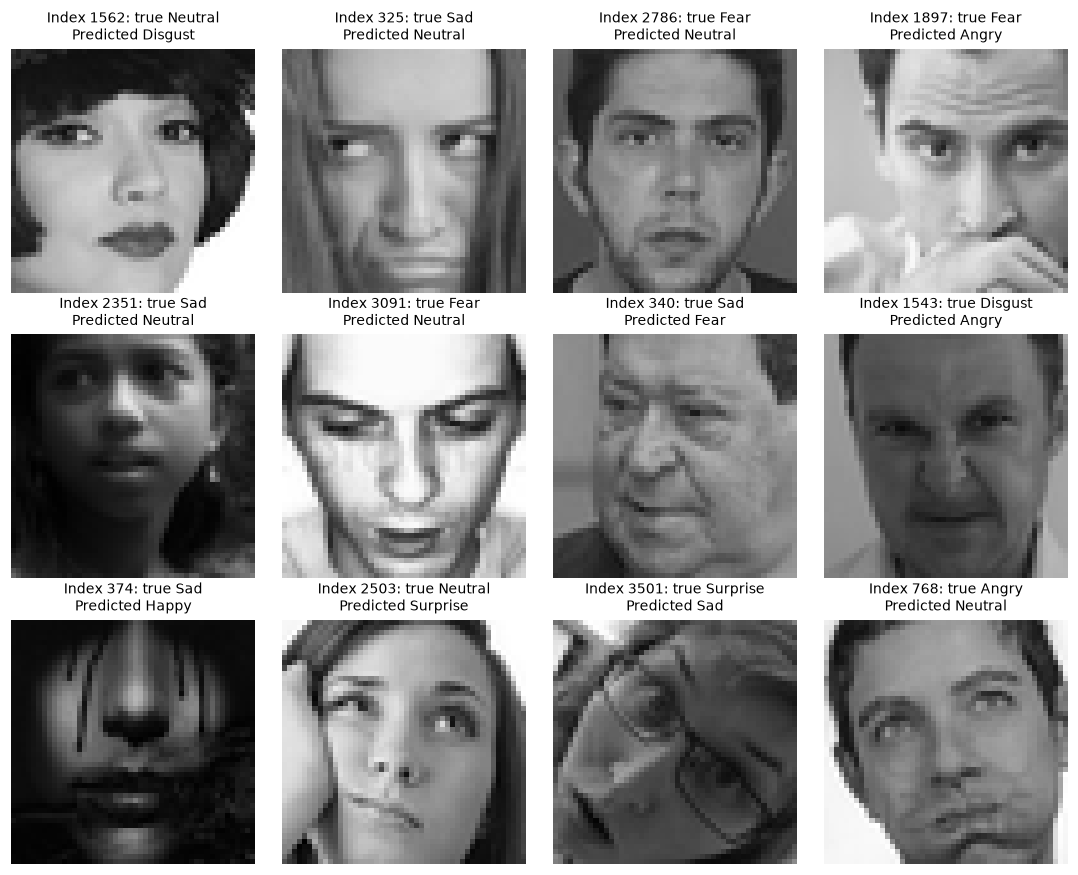

In [7]:
def plot_confusion_grid(predictions_by_model, actual, split):
    fig, axes = plt.subplots(3, 3, figsize=(17, 15))
    for ax, (key, predicted) in zip(axes.flat, predictions_by_model.items()):
        ConfusionMatrixDisplay.from_predictions(actual, predicted, labels=LABELS,
            display_labels=EMOTIONS, normalize='true', cmap='Blues',
            values_format='.2f', colorbar=False, ax=ax, xticks_rotation=45)
        ax.set_title(f'{key[0]} + {key[1]}', fontsize=10)
    fig.suptitle(f'{split}: row-normalized confusion matrices', y=1.01)
    plt.tight_layout()
    fig.savefig(OUT / f'{split}_confusion_matrices.png', bbox_inches='tight')
    plt.show()

plot_confusion_grid(validation_predictions, y['validation'], 'validation')
best_val_pred = validation_predictions[best_key]
validation_class_report = pd.DataFrame(classification_report(
    y['validation'], best_val_pred, labels=LABELS, target_names=EMOTIONS,
    output_dict=True, zero_division=0)).T
display(validation_class_report.round(4))
validation_class_report.to_csv(OUT / 'selected_validation_classification_report.csv')
mistakes = np.flatnonzero(best_val_pred != y['validation'])
chosen = np.random.default_rng(SEED).choice(mistakes, size=min(12, len(mistakes)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax in axes.flat:
    ax.axis('off')
for ax, index in zip(axes.flat, chosen):
    ax.imshow(images['validation'][index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Index {index}: true {EMOTIONS[y["validation"][index]]}\n'
                 f'Predicted {EMOTIONS[best_val_pred[index]]}', fontsize=9)
plt.tight_layout()
fig.savefig(OUT / 'validation_mistakes.png', bbox_inches='tight')
plt.show()

### 1.8 Freeze configurations, then evaluate PrivateTest
All nine configurations and the overall winner are now fixed using validation data.
We save that decision before evaluating PrivateTest. For a consistent comparison,
the models remain fitted on Training only (no train + validation refit).
Test results describe these fixed models; they must not change the selected winner
or trigger further tuning. The same nine configurations are reported on both splits.

Loaded: landmarks_test_0790c80d62d07b5a.npy
Loaded: hog_test_1da0394a8a5338dc.npy


,feature,classifier,accuracy,balanced_accuracy,macro_f1,selected_on_validation
0,landmarks,Logistic Regression,0.4497,0.3845,0.3842,False
1,landmarks,Linear SVM,0.4394,0.3512,0.3224,False
2,landmarks,Random Forest,0.4558,0.3896,0.3937,False
3,hog,Logistic Regression,0.4319,0.4036,0.3963,True
4,hog,Linear SVM,0.4369,0.3727,0.3726,False
5,hog,Random Forest,0.4533,0.3793,0.3933,False
6,pca,Logistic Regression,0.3720,0.2988,0.2892,False
7,pca,Linear SVM,0.3667,0.2877,0.2632,False
8,pca,Random Forest,0.3725,0.2898,0.2893,False


Final test scores of the validation-selected model:


,feature,classifier,accuracy,balanced_accuracy,macro_f1,selected_on_validation
3,hog,Logistic Regression,0.4319,0.4036,0.3963,True


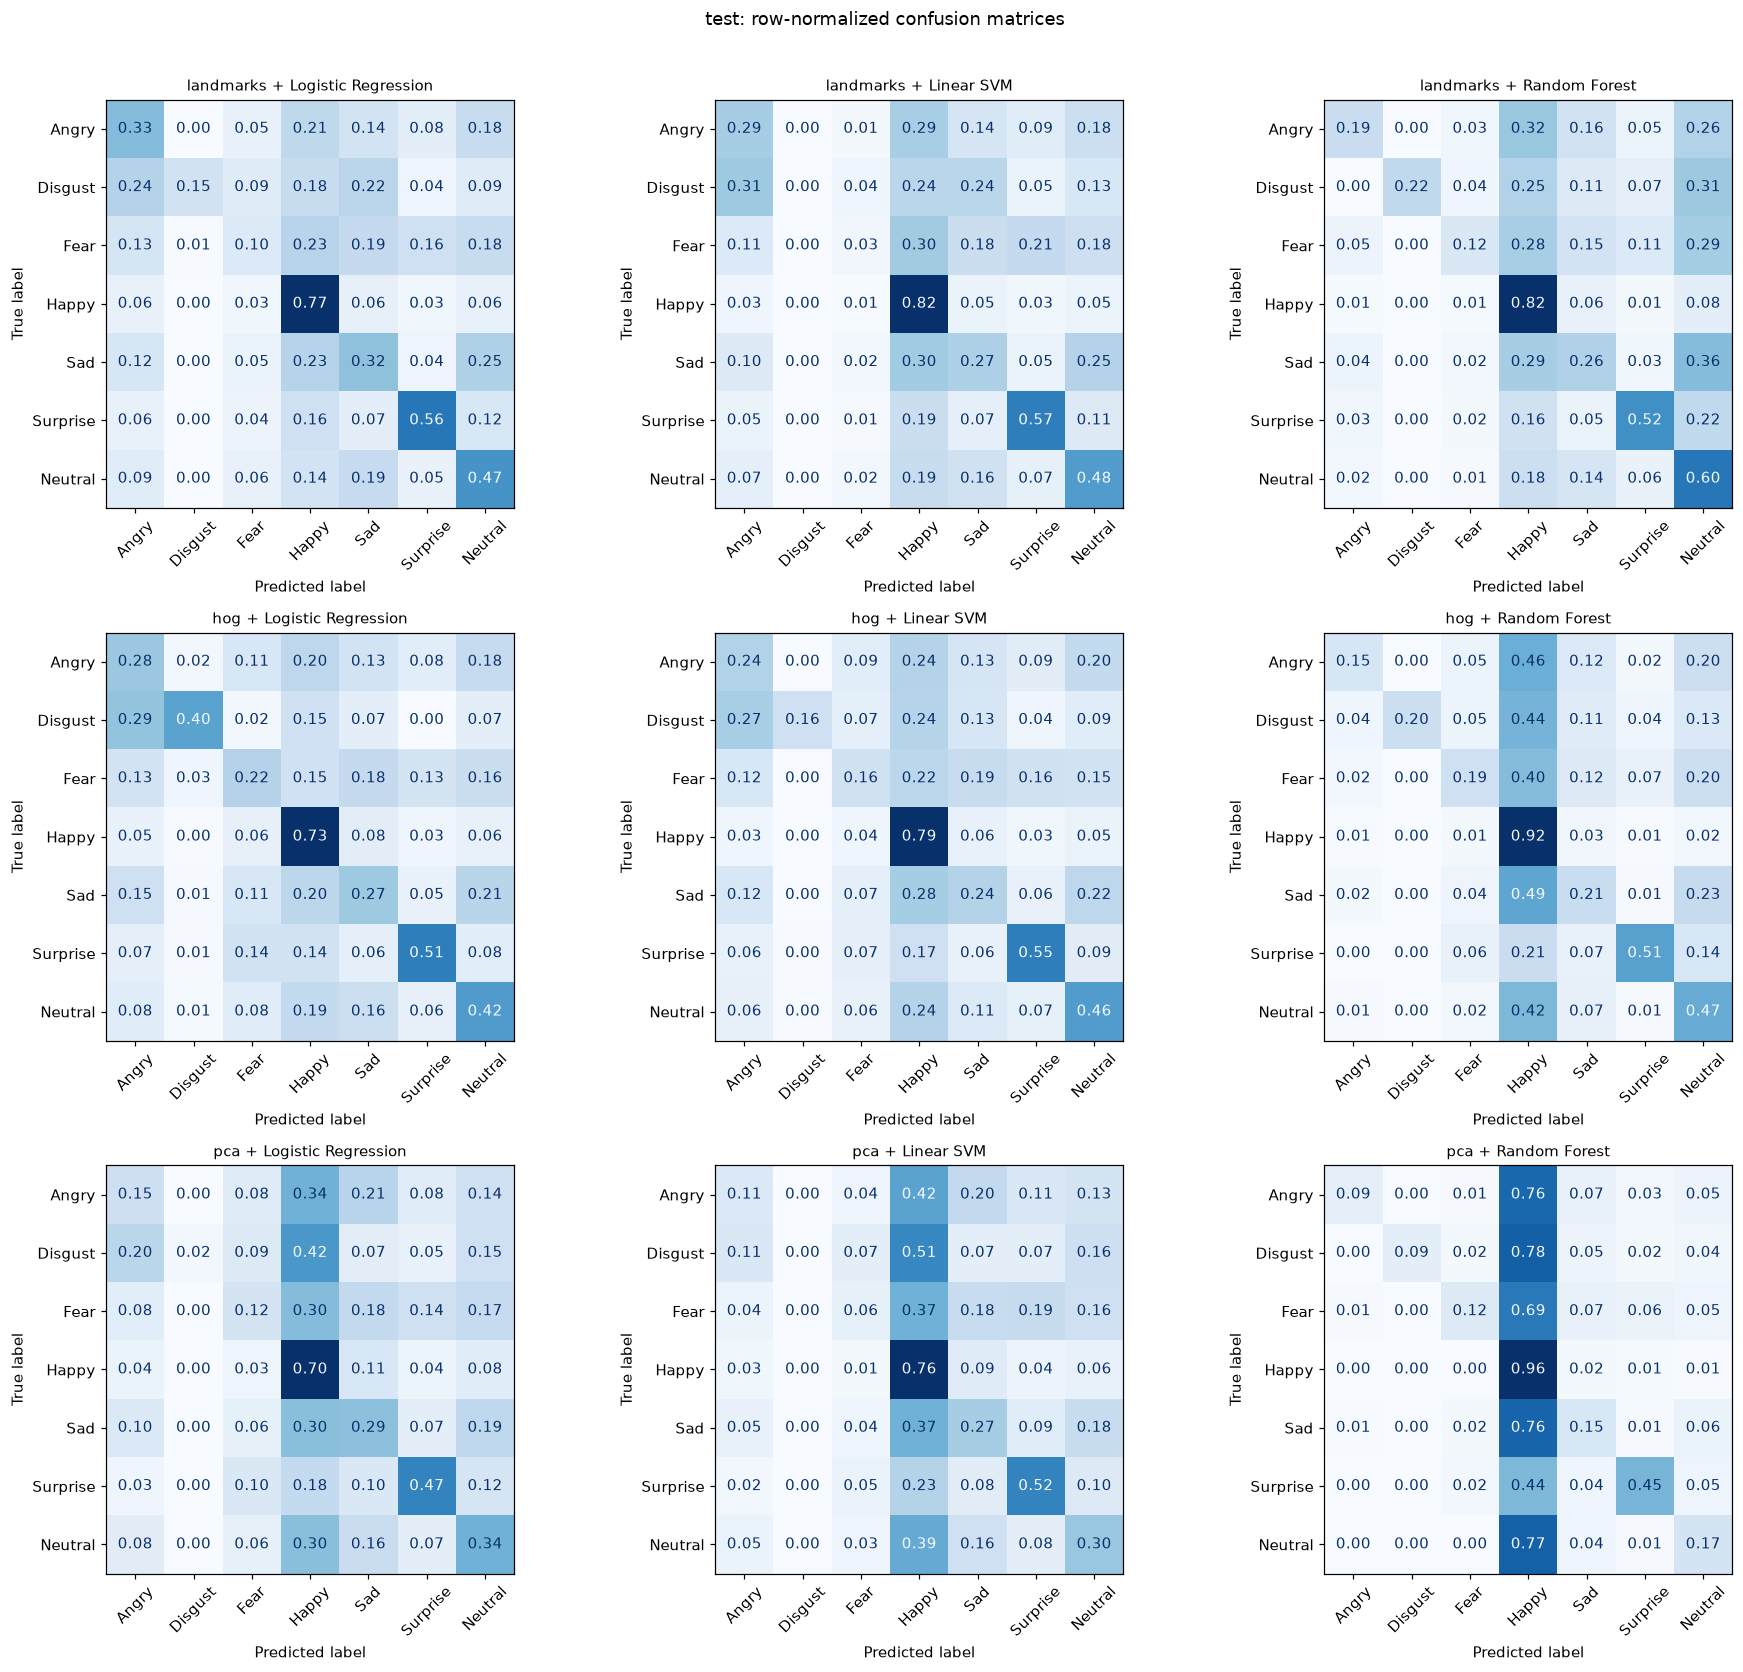

,precision,recall,f1-score,support
Angry,0.3141,0.2770,0.2944,491.0000
Disgust,0.3492,0.4000,0.3729,55.0000
Fear,0.2932,0.2216,0.2524,528.0000
Happy,0.5721,0.7270,0.6403,879.0000
Sad,0.3102,0.2710,0.2893,594.0000
Surprise,0.5121,0.5072,0.5097,416.0000
Neutral,0.4087,0.4217,0.4151,626.0000
accuracy,0.4319,0.4319,0.4319,0.4319
macro avg,0.3942,0.4036,0.3963,3589.0000
weighted avg,0.4136,0.4319,0.4193,3589.0000


In [8]:
selection = {'selection_split': 'PublicTest', 'selection_metric': 'macro_f1',
             'selected_feature': best_feature, 'selected_classifier': best_classifier,
             'training_split': 'Training', 'seed': SEED,
             'dataset_sha256': dataset_hash,
             'configurations': [{'feature': key[0], 'classifier': key[1],
                                 'parameters': str(model.get_params())}
                                for key, model in models.items()]}
(OUT / 'frozen_selection.json').write_text(json.dumps(selection, indent=2), encoding='utf-8')

images['test'] = decode_images(split_frames['test'])
features['landmarks']['test'] = cached_features('landmarks', 'test', images['test'])
features['hog']['test'] = cached_features('hog', 'test', images['test'])
features['pca']['test'] = pca.transform(pixel_vectors(images['test']))
test_predictions, test_rows = {}, []
for key, model in models.items():
    predicted = model.predict(features[key[0]]['test'])
    test_predictions[key] = predicted
    test_rows.append({'feature': key[0], 'classifier': key[1],
                      **metric_scores(y['test'], predicted),
                      'selected_on_validation': key == best_key})
test_results = pd.DataFrame(test_rows)
test_results.to_csv(OUT / 'test_results.csv', index=False)
display(test_results.round(4))
print('Final test scores of the validation-selected model:')
display(test_results.loc[test_results.selected_on_validation].round(4))
plot_confusion_grid(test_predictions, y['test'], 'test')
test_class_report = pd.DataFrame(classification_report(
    y['test'], test_predictions[best_key], labels=LABELS, target_names=EMOTIONS,
    output_dict=True, zero_division=0)).T
display(test_class_report.round(4))
test_class_report.to_csv(OUT / 'selected_test_classification_report.csv')

### 1.9 Save reusable models, preprocessing, and predictions
Each bundle contains the trained classifier (including its scaler where applicable),
feature settings, label mapping, and the fitted PCA when needed. Landmark extraction
also requires the external predictor identified by its checksum. These bundles can
be reused in later notebook tasks; the original supplied model is not overwritten.

In [9]:
for key, model in models.items():
    feature_name, classifier_name = key
    slug = f'{feature_name}_{classifier_name.lower().replace(" ", "_")}'
    bundle = {'classifier': model, 'feature_type': feature_name,
              'pca': pca if feature_name == 'pca' else None,
              'hog_settings': HOG_SETTINGS if feature_name == 'hog' else None,
              'landmark_predictor': str(PREDICTOR.relative_to(ROOT)) if feature_name == 'landmarks' else None,
              'landmark_predictor_sha256': predictor_hash if feature_name == 'landmarks' else None,
              'landmark_rectangle': [1, 1, 47, 47],
              'landmark_normalization': 'center then divide each axis by max absolute coordinate',
              'image_shape': (48, 48), 'input_dtype': 'uint8', 'input_range': [0, 255],
              'emotion_names': EMOTIONS, 'seed': SEED,
              'selected_on_validation': key == best_key}
    joblib.dump(bundle, MODEL_DIR / f'{slug}.pkl', compress=3)
    for split, predictions_by_model in [('validation', validation_predictions), ('test', test_predictions)]:
        predicted = predictions_by_model[key]
        pd.DataFrame({'split_row_index': np.arange(len(predicted)),
                      'actual': y[split], 'predicted': predicted}).to_csv(
                          OUT / f'{split}_{slug}_predictions.csv', index=False)
        np.savetxt(OUT / f'{split}_{slug}_confusion_counts.csv',
                   confusion_matrix(y[split], predicted, labels=LABELS), delimiter=',', fmt='%d')

versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'pandas', 'scikit-learn', 'scikit-image', 'matplotlib', 'joblib']}
versions['dlib'] = dlib.__version__
versions['python'] = sys.version
(OUT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
print('Models:', MODEL_DIR.relative_to(ROOT))
print('Tables, figures, and predictions:', OUT.relative_to(ROOT))

Models: models\task1
Tables, figures, and predictions: results\task1


### 1.10 Observations and conclusions for Task 1

**Experimental protocol.** We compared all nine combinations of Logistic Regression, linear SVM, and Random Forest with landmarks, HOG, and PCA features. The official splits contain 28,709 training, 3,589 validation, and 3,589 test images. PCA and classifier scalers were fitted on Training only. Model selection used PublicTest macro-F1; all configurations were fixed before evaluating PrivateTest. The models were not refitted on train + validation.

**Classifier selection and the metric trade-off.** HOG + Logistic Regression achieved the highest validation macro-F1 (0.3991) and balanced accuracy (0.4017), so it was selected. HOG + linear SVM had the highest validation accuracy (0.4478), demonstrating that the ranking depends on the metric. The selected configuration obtained 0.4319 accuracy, 0.4036 balanced accuracy, and 0.3963 macro-F1 on PrivateTest. Its validation and test macro-F1 differ by only 0.0029; this is descriptive agreement between these splits, not proof of general robustness.

| Configuration | Test accuracy | Test balanced accuracy | Test macro-F1 |
|---|---:|---:|---:|
| HOG + Logistic Regression (selected on validation) | 0.4319 | 0.4036 | 0.3963 |
| Landmarks + Random Forest (supplied baseline) | 0.4558 | 0.3896 | 0.3937 |
| HOG + Random Forest | 0.4533 | 0.3793 | 0.3933 |

The selected model has the highest test macro-F1 and balanced accuracy among the fixed configurations, while landmark + Random Forest has the highest test accuracy. Its macro-F1 advantage over that forest is only 0.0026 (0.26 percentage points). Without uncertainty estimates or repeated experiments, we should not describe this small difference as statistically significant. Macro-F1 gives equal weight to each emotion's F1; balanced accuracy is the mean class recall. Both complement accuracy because Training contains 7,215 Happy images but only 436 Disgust images.

**Feature comparison.** HOG obtained higher validation macro-F1 than landmarks and PCA for each of the three classifiers. On the test split, HOG also led for Logistic Regression and linear SVM, but Random Forest performed slightly better with landmarks (0.3937) than HOG (0.3933). Thus HOG is the strongest overall feature choice in this experiment, with a classifier-dependent exception. HOG encodes local edge structure, whereas landmarks encode facial geometry. The overlay examples show that landmark placement can be unreliable on rotated faces. These observations suggest possible reasons for the results, but do not establish their causes.

PCA was weakest for all three classifiers on both splits. Its 150 components retained approximately 92.3% of training pixel variance, yet this did not translate into strong emotion classification. Retaining image variance does not guarantee retaining the information most useful for distinguishing emotion labels. This conclusion applies to this raw-pixel PCA configuration, not every possible use of PCA.

**Difficult emotions in the selected model.** On PrivateTest, Fear had the lowest F1 (0.2524), followed by Sad (0.2893) and Angry (0.2944). Their recalls were 22.16%, 27.10%, and 27.70%, respectively. Happy was easiest (F1 0.6403; recall 72.70%), followed by Surprise (F1 0.5097). For example, 125/594 Sad images were predicted Neutral (21.04%), and 97/528 Fear images were predicted Sad (18.37%). These are examples of errors, not the majority of either class. Disgust's test F1 was 0.3729, but its test support is only 55 images, so that estimate should be interpreted cautiously.

**Visual evidence.** The validation error gallery includes a Fear image with a hand covering the lower face (index 1897), a dark Sad image with hair covering much of the face (index 374), and a strongly tilted Surprise face (index 3501). These illustrate occlusion, illumination differences, and pose variation among mistakes. Other examples, such as Sad predicted Neutral (index 325), show potentially subtle expression differences. Visual inspection alone does not establish that a label is incorrect or that a particular nuisance factor caused the mistake.

**Scope and next step.** These are reproducible baselines with fixed hyperparameters, no class balancing, and a linear SVM; they do not establish an optimal classifier or feature representation. Extensive tuning, balancing, and feature improvements belong to Task 5 and must use training/validation data rather than test feedback. HOG is the feature representation to carry forward into Task 2, where the corresponding classifiers will be retrained on KDEF. The report should include the required AI-use declaration and describe the assistance actually used for code and interpretation.


## 2. KDEF Dataset Study (15%).

## 3. Cross-Dataset Generalization (20%)


## 4. Explainable Fuzzy Classifier (10%)

## 5. Creative Challenge (25%)

## 6. Run your models in a real-time a real-time emotion recognition program with your laptop (10%)